# HW2 Part 2: Single-Stock Risk Report

**Author:** Nirmit Ghughu

This is a **parameterized** report template. Part 3 (`03_run_all_stocks.py`) executes it with papermill once per ticker, replacing the values in the cell tagged `parameters`.

It reads `ohlc_hw_cleaned`, the validated table written by `01_data_cleaning.ipynb`, and:
1. loads and validates one ticker over the requested window, disclosing the **actual** coverage
2. computes daily log returns, 20-day rolling volatility, drawdown and the Sharpe ratio
3. draws a 2×2 risk dashboard
4. builds a summary table and exports the key numbers with scrapbook, so the batch script can collect them

**Conventions.** All metrics use **adjusted close**, so dividends and splits do not show up as fake losses. Daily returns are **log returns**, `ln(P_t / P_{t-1})`. Values stay fractions in calculations and exports, and are formatted as percentages only for display.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 160)

TRADING_DAYS = 252                     # annualization convention used throughout the course
COLORS = {                             # one palette for every panel
    'high': '#c0392b', 'low': '#27ae60', 'warmup': '#95a5a6',
    'ma': '#2c3e50', 'vol': '#8e44ad', 'drawdown': '#e74c3c',
}

## 2.1 Parameters

The next cell is tagged `parameters` in its cell metadata, so papermill injects new values after it. `db_path` may be relative to this notebook's folder or absolute. The batch script passes an absolute path, so the report does not depend on the working directory.

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local working copy that holds ohlc_hw_cleaned
volatility_window = 20  # Rolling window (returns) for volatility
risk_free_rate = 0.02  # Annual risk-free rate for the Sharpe ratio

In [3]:
# Parameters
ticker = "MRK"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/nirmitghughu/Desktop/Projects Interview Prep/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Nirmit_Ghughu/data/data.db"


## 2.2 Load and validate the data

The query uses SQL placeholders instead of string formatting, and opens the database **read-only** because a report should never change its source. Before computing anything, the report checks that:
- the parameters make sense (`start_date <= end_date`, window of at least 2)
- the ticker has data in the window
- there is enough history for a full volatility window. 20 returns need **21 prices**, because the first price has no previous price to compare with.
- the cleaned data still passes the Part 1 rules: finite positive prices, valid OHLC bounds and one row per date

In [4]:
ticker = str(ticker).strip().upper()
start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
if start > end:
    raise ValueError(f'start_date {start_date} is after end_date {end_date}.')
if not isinstance(volatility_window, int) or isinstance(volatility_window, bool) or volatility_window < 2:
    raise ValueError('volatility_window must be an integer >= 2.')

database = Path(db_path).expanduser().resolve()
if not database.is_file():
    raise FileNotFoundError(f'{database} not found. Run 01_data_cleaning.ipynb first to create ohlc_hw_cleaned.')

query = """
    SELECT ts, open, high, low, close, adj_close, volume,
           extreme_return_flag, spike_reversal_flag, zero_volume_flag, price_repair, adj_close_repair
    FROM ohlc_hw_cleaned
    WHERE ticker = ? AND ts >= ? AND ts <= ?
    ORDER BY ts
"""
with closing(sqlite3.connect(database.as_uri() + '?mode=ro', uri=True)) as conn:
    df = pd.read_sql_query(query, conn, params=(ticker, start.strftime('%Y-%m-%d'), end.strftime('%Y-%m-%d')),
                           parse_dates=['ts'], index_col='ts')

min_prices = volatility_window + 1
if df.empty:
    raise ValueError(f'{ticker}: no rows in ohlc_hw_cleaned between {start_date} and {end_date}.')
if len(df) < min_prices:
    raise ValueError(f'{ticker}: only {len(df)} prices between {start_date} and {end_date}; '
                     f'a {volatility_window}-return volatility window needs at least {min_prices}.')

first_date, last_date = df.index.min(), df.index.max()
print(f'{ticker} from {start_date} to {end_date}: {len(df)} trading days')
print(f'Actual coverage: {first_date.date()} to {last_date.date()}')

MRK from 2024-06-01 to 2024-11-30: 126 trading days
Actual coverage: 2024-06-03 to 2024-11-29


In [5]:
def check_quality(frame):
    """Count rows that break the Part 1 cleaning rules; every count should be zero."""
    prices = frame[['open', 'high', 'low', 'close', 'adj_close']]
    return pd.Series({
        'missing or non-finite price': int((~np.isfinite(prices)).any(axis=1).sum()),
        'nonpositive price': int(prices.le(0).any(axis=1).sum()),
        'low <= open/close <= high broken': int((frame['low'].gt(frame[['open', 'close']].min(axis=1))
                                                 | frame['high'].lt(frame[['open', 'close']].max(axis=1))).sum()),
        'negative or missing volume': int((frame['volume'].isna() | frame['volume'].lt(0)).sum()),
        'duplicate dates': int(frame.index.duplicated().sum()),
    }, name='violations')


quality = check_quality(df)
display(quality.to_frame())
if quality.any():
    raise ValueError(f'{ticker}: cleaned data failed validation: {quality[quality > 0].to_dict()}')

# Review flags carried over from Part 1. They are information, not errors.
review_flags = df[['extreme_return_flag', 'spike_reversal_flag', 'zero_volume_flag']].sum()
repaired_rows = int(df['price_repair'].ne('none').sum() + df['adj_close_repair'].ne('none').sum())
print('Part 1 review flags in this window:', review_flags.to_dict(), '| repaired values:', repaired_rows)

,violations
missing or non-finite price,0
nonpositive price,0
low <= open/close <= high broken,0
negative or missing volume,0
duplicate dates,0


Part 1 review flags in this window: {'extreme_return_flag': 1, 'spike_reversal_flag': 0, 'zero_volume_flag': 0} | repaired values: 9


In [6]:
# Disclose coverage honestly: the requested window is not necessarily the observed window.
coverage_gap_days = (end - last_date).days
if coverage_gap_days > 7:
    coverage_note = (f'Note: {ticker} data ends on {last_date.date()}, {coverage_gap_days} calendar days before the '
                     f'requested end {end_date}. Metrics cover only the observed period, so compare them '
                     'with care against stocks that have the full window.')
else:
    coverage_note = f'{ticker} data covers the requested window ({first_date.date()} to {last_date.date()}).'
print(coverage_note)

display(df[['open', 'high', 'low', 'close', 'adj_close', 'volume']].head())
display(df[['open', 'high', 'low', 'close', 'adj_close', 'volume']].tail())

MRK data covers the requested window (2024-06-03 to 2024-11-29).


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,125.77,128.95,125.77,128.42,126.81,7702676
2024-06-04,127.15,129.36,126.88,128.71,127.09,6440167
2024-06-05,128.48,129.94,128.07,129.45,127.82,5009502
2024-06-06,129.16,130.93,128.90,130.52,128.88,8088641
2024-06-07,130.35,131.37,130.21,130.67,129.03,4945600


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-22,100.33,101.79,98.93,99.18,99.18,14031200
2024-11-25,100.09,101.74,99.51,101.16,101.16,34659100
2024-11-26,101.48,101.80,99.70,101.62,101.62,9324100
2024-11-27,101.65,103.45,101.64,103.12,103.12,9802200
2024-11-29,102.88,103.04,101.53,101.64,101.64,6081200


## 2.3 Risk metrics

Each function is short, documented, and checked on a tiny hand-computable example before it touches real data.

| Metric | Formula | Notes |
|---|---|---|
| Daily log return | `ln(P_t / P_{t-1})` | first value is missing, **not** a zero-return day |
| Rolling volatility | `std(last 20 log returns) × √252` | sample std (`ddof=1`); missing until 20 returns exist |
| Drawdown | `P_t / max(P_0..P_t) − 1` | per-date value, can recover; **maximum drawdown** is its minimum |
| Sharpe ratio | `(mean × 252 − r_f) / (std × √252)` | course approximation with `r_f` = 2%; `N/A` when std is zero or undefined |

In [7]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Daily log returns ln(P_t / P_{t-1}); the first value is NaN because there is no previous price.

    Requires prices sorted by date, finite and positive.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Annualized rolling volatility: sample std of the last `window` daily returns times sqrt(252).

    The first `window` dates are NaN (warm-up) and are deliberately not filled.
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Per-date drawdown from the running price peak, (price - cum_max) / cum_max.

    The name follows the assignment. The result is the drawdown on each date (0 at a new high);
    the maximum drawdown for the summary is `drawdown.min()`.
    """
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Annualized Sharpe ratio, (mean * 252 - rf) / (std * sqrt(252)), from daily returns.

    Missing returns are ignored. Returns NaN when there are fewer than two returns or the
    standard deviation is zero, because the ratio is undefined there.
    """
    observed = returns.dropna()
    sigma = observed.std()
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return (observed.mean() * TRADING_DAYS - risk_free_rate) / (sigma * np.sqrt(TRADING_DAYS))

In [8]:
# Hand-checkable examples: if one of these fails, the real report would be wrong too.
toy_prices = pd.Series([80.0, 100.0, 70.0, 85.0])

toy_returns = calculate_returns(toy_prices)
assert pd.isna(toy_returns.iloc[0])
np.testing.assert_allclose(toy_returns.iloc[1:], np.log([100 / 80, 70 / 100, 85 / 70]))

toy_drawdown = calculate_max_drawdown(toy_prices)
np.testing.assert_allclose(toy_drawdown, [0.0, 0.0, -0.30, -0.15])   # worst -30%, but final only -15%

toy_vol = calculate_volatility(pd.Series([0.01, -0.01, 0.01, -0.01]), window=2)
assert toy_vol.isna().iloc[0]                                        # warm-up stays missing
assert np.isclose(toy_vol.iloc[1], np.std([0.01, -0.01], ddof=1) * np.sqrt(252))

assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01, 0.01])))      # zero volatility -> undefined
assert pd.isna(calculate_sharpe_ratio(pd.Series([np.nan, 0.01])))    # a single return -> undefined

display(pd.DataFrame({'price': toy_prices, 'log_return': toy_returns, 'drawdown': toy_drawdown}))
print('All metric checks passed.')

,price,log_return,drawdown
0,80.0,NaN,0.00
1,100.0,0.223144,0.00
2,70.0,-0.356675,-0.30
3,85.0,0.194156,-0.15


All metric checks passed.


In [9]:
df['log_return'] = calculate_returns(df['adj_close'])
df['volatility'] = calculate_volatility(df['log_return'], volatility_window)
df['ma_50'] = df['adj_close'].rolling(50).mean()
df['drawdown'] = calculate_max_drawdown(df['adj_close'])

returns = df['log_return'].dropna()
n_returns = len(returns)
sharpe_ratio = calculate_sharpe_ratio(returns, risk_free_rate)
max_drawdown = df['drawdown'].min()
max_drawdown_date = df['drawdown'].idxmin()
mean_volatility = df['volatility'].mean()

# The rolling window is missing exactly until `volatility_window` returns exist.
assert df['volatility'].iloc[:volatility_window].isna().all()
assert df['volatility'].iloc[volatility_window:].notna().all()

display(df[['adj_close', 'log_return', 'volatility', 'ma_50', 'drawdown']].iloc[volatility_window - 2:volatility_window + 3])
print(f'Log returns: {n_returns} | Sharpe ratio: {sharpe_ratio:.2f} | '
      f'Maximum drawdown: {max_drawdown:.2%} on {max_drawdown_date.date()} | '
      f'Mean {volatility_window}-day volatility: {mean_volatility:.2%}')

,adj_close,log_return,volatility,ma_50,drawdown
ts,,,,,
2024-06-28,122.98,-0.047481,NaN,NaN,-0.068898
2024-07-01,127.05,0.032559,NaN,NaN,-0.038083
2024-07-02,126.87,-0.001418,0.246352,NaN,-0.039446
2024-07-03,125.01,-0.014769,0.251669,NaN,-0.053528
2024-07-05,125.61,0.004788,0.251367,NaN,-0.048985


Log returns: 125 | Sharpe ratio: -1.93 | Maximum drawdown: -27.08% on 2024-11-15 | Mean 20-day volatility: 23.27%


## 2.4 Visualization

How to read the four panels:
- **Price and 50-day MA**: each price segment is colored by that day's 20-day volatility. Red is above the report's mean volatility, green is at or below it, and gray is the warm-up period before the estimate exists. The coloring is **retrospective**, because the threshold uses the whole window.
- **Daily returns**: green bars are up days and red bars are down days.
- **Rolling volatility**: shading shows where volatility is above (red) or below (green) its mean.
- **Drawdown**: how far the price sits below its running peak. The worst point is marked.

The 50-day moving average needs 50 prices, so it starts about two and a half months into the window, and it is absent if the report has fewer prices.

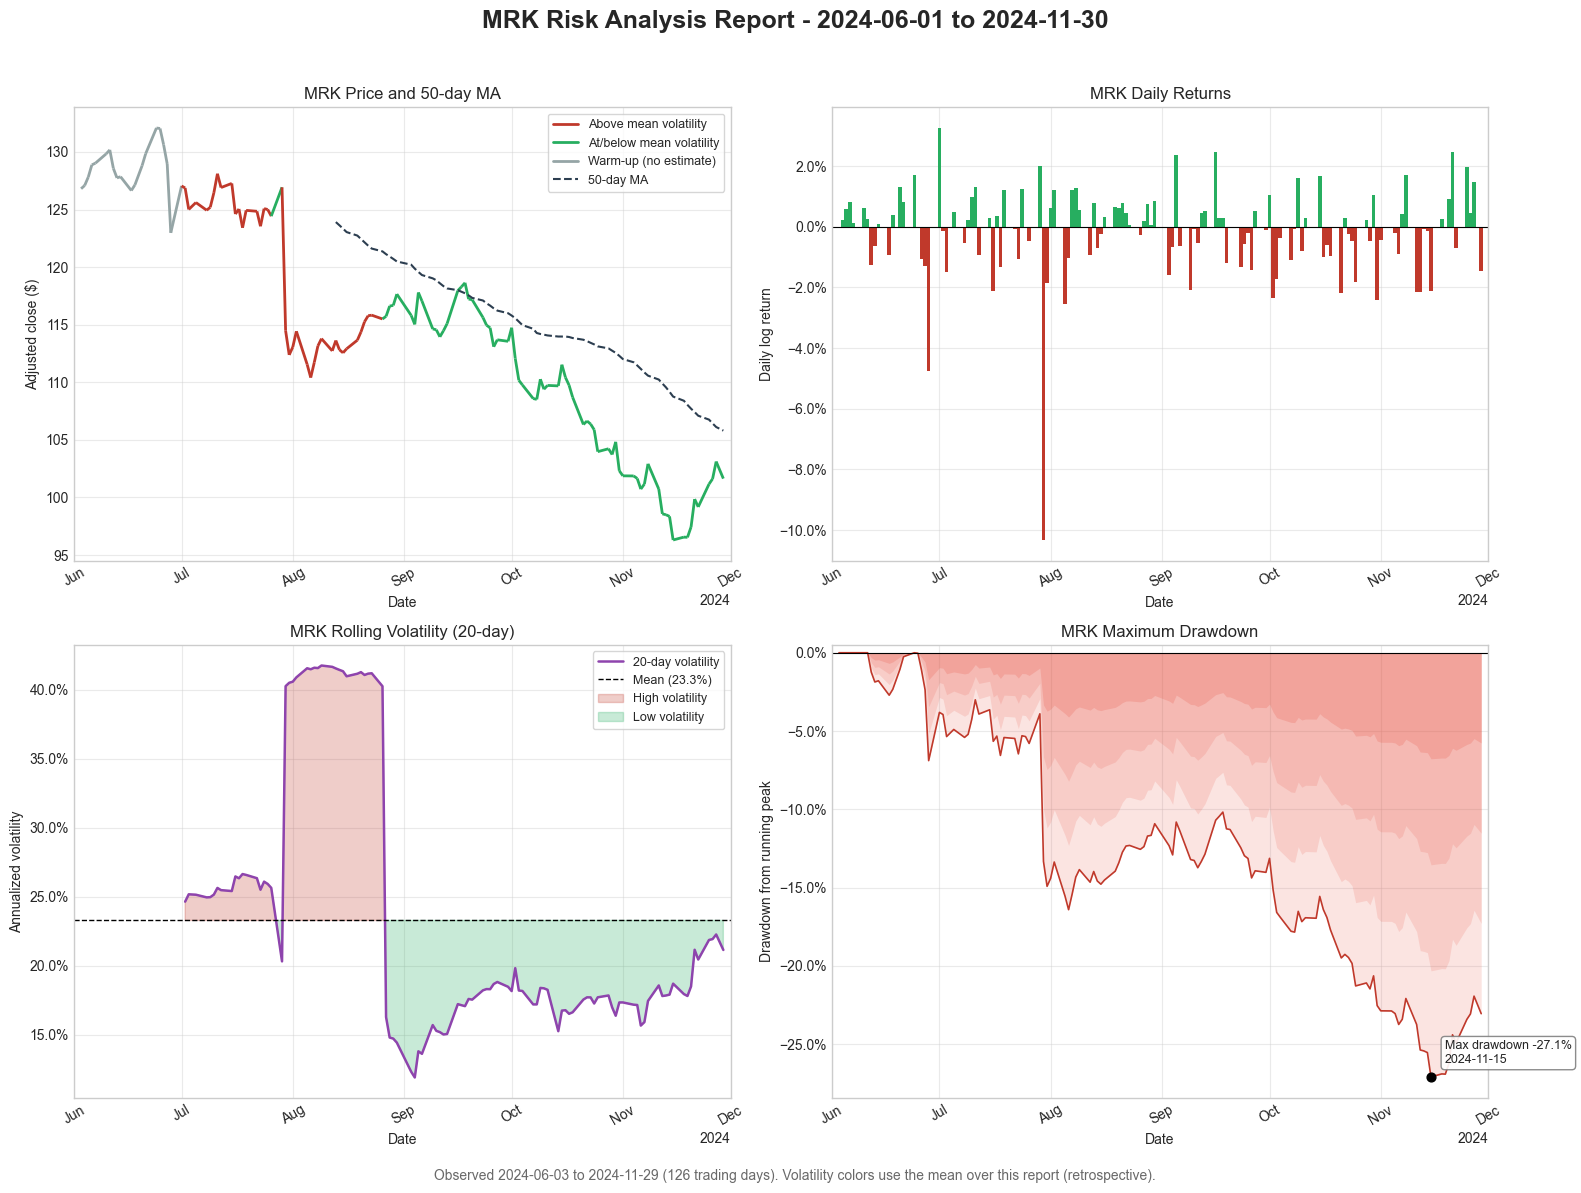

In [10]:
def plot_price_by_volatility(ax, frame, threshold):
    """Adjusted close as line segments colored by volatility regime, plus the 50-day moving average."""
    x = mdates.date2num(frame.index.to_pydatetime())
    points = np.column_stack([x, frame['adj_close'].to_numpy()])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    vol = frame['volatility'].to_numpy()[1:]                  # the segment ending on day t uses day t's volatility
    colors = np.where(np.isnan(vol), COLORS['warmup'], np.where(vol > threshold, COLORS['high'], COLORS['low']))
    ax.add_collection(LineCollection(segments, colors=colors, linewidth=2))
    ax.autoscale_view()

    handles = [Line2D([], [], color=COLORS['high'], lw=2, label='Above mean volatility'),
               Line2D([], [], color=COLORS['low'], lw=2, label='At/below mean volatility'),
               Line2D([], [], color=COLORS['warmup'], lw=2, label='Warm-up (no estimate)')]
    if frame['ma_50'].notna().any():
        handles += ax.plot(frame.index, frame['ma_50'], color=COLORS['ma'], lw=1.5, ls='--', label='50-day MA')
    else:
        ax.text(0.02, 0.04, f'50-day MA unavailable: only {len(frame)} prices', transform=ax.transAxes, fontsize=9)
    ax.legend(handles=handles, loc='best', fontsize=9, frameon=True)


fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=18, fontweight='bold')

# Top left: price colored by volatility regime
ax = axes[0, 0]
plot_price_by_volatility(ax, df, mean_volatility)
ax.set(title=f'{ticker} Price and 50-day MA', ylabel='Adjusted close ($)')

# Top right: daily returns
ax = axes[0, 1]
ax.bar(df.index, df['log_return'], width=1.0,
       color=np.where(df['log_return'] >= 0, COLORS['low'], COLORS['high']))
ax.axhline(0, color='black', lw=0.8)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(title=f'{ticker} Daily Returns', ylabel='Daily log return')

# Bottom left: rolling volatility with regime shading
ax = axes[1, 0]
vol = df['volatility']
ax.plot(df.index, vol, color=COLORS['vol'], lw=1.8, label=f'{volatility_window}-day volatility')
ax.axhline(mean_volatility, color='black', ls='--', lw=1, label=f'Mean ({mean_volatility:.1%})')
ax.fill_between(df.index, vol, mean_volatility, where=vol > mean_volatility,
                color=COLORS['high'], alpha=0.25, interpolate=True, label='High volatility')
ax.fill_between(df.index, vol, mean_volatility, where=vol <= mean_volatility,
                color=COLORS['low'], alpha=0.25, interpolate=True, label='Low volatility')
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(title=f'{ticker} Rolling Volatility ({volatility_window}-day)', ylabel='Annualized volatility')
ax.legend(loc='best', fontsize=9, frameon=True)

# Bottom right: drawdown area with a layered red/pink gradient
ax = axes[1, 1]
for fraction, alpha in [(1.0, 0.15), (0.75, 0.15), (0.5, 0.15), (0.25, 0.2)]:
    ax.fill_between(df.index, df['drawdown'] * fraction, 0, color=COLORS['drawdown'], alpha=alpha, lw=0)
ax.plot(df.index, df['drawdown'], color=COLORS['high'], lw=1.2)
ax.scatter([max_drawdown_date], [max_drawdown], color='black', zorder=3, s=40)
ax.annotate(f'Max drawdown {max_drawdown:.1%}\n{max_drawdown_date.date()}', (max_drawdown_date, max_drawdown),
            xytext=(10, 10), textcoords='offset points', fontsize=9,
            bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.9))
ax.axhline(0, color='black', lw=0.8)
ax.set_ylim(top=0.005)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(title=f'{ticker} Maximum Drawdown', ylabel='Drawdown from running peak')

for ax in axes.flat:
    ax.grid(True, alpha=0.4)
    ax.set_xlabel('Date')
    ax.set_xlim(first_date - pd.Timedelta(days=2), last_date + pd.Timedelta(days=2))   # same dates on every panel
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.tick_params(axis='x', labelrotation=30)

fig.text(0.5, 0.005, f'Observed {first_date.date()} to {last_date.date()} ({len(df)} trading days). '
         'Volatility colors use the mean over this report (retrospective).', ha='center', fontsize=10, color='dimgray')
fig.tight_layout(rect=(0, 0.02, 1, 0.96))
plt.show()

## 2.5 Summary statistics

Definitions follow the assignment:
- **Total return** = `last adj close / first adj close − 1`
- **Annualized return** = `exp(sum(log returns) × 252 / n) − 1`, compounded over the `n` observed returns
- **Annualized volatility** = whole-period `std(log returns) × √252`. This is a different number from the *mean rolling* volatility used in Part 3.
- **Best/worst day** and **average up/down day** use log returns. **Positive days** = positive returns ÷ all nonmissing returns, so zero-return days count in the denominator.

Undefined values are shown as `N/A`.

In [11]:
up_days, down_days = returns[returns > 0], returns[returns < 0]
summary_metrics = pd.Series({
    'Total Return': df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1,
    'Annualized Return': np.expm1(returns.sum() * TRADING_DAYS / n_returns),
    'Annualized Volatility': returns.std() * np.sqrt(TRADING_DAYS),
    'Sharpe Ratio': sharpe_ratio,
    'Maximum Drawdown': max_drawdown,
    'Best Day': returns.max(),
    'Worst Day': returns.min(),
    'Positive Days': (returns > 0).sum() / n_returns,
    'Average Up Day': up_days.mean() if len(up_days) else np.nan,
    'Average Down Day': down_days.mean() if len(down_days) else np.nan,
})

# Consistency check: compounding the log returns reproduces the total return.
assert np.isclose(np.expm1(returns.sum()), summary_metrics['Total Return'])

SIGNED = {'Total Return', 'Annualized Return', 'Best Day', 'Worst Day', 'Average Up Day', 'Average Down Day', 'Maximum Drawdown'}


def format_metric(name, value):
    """Display-only formatting; the underlying values stay fractions."""
    if pd.isna(value):
        return 'N/A'
    if name == 'Sharpe Ratio':
        return f'{value:.2f}'
    return f'{value:+.2%}' if name in SIGNED else f'{value:.2%}'


summary_table = pd.DataFrame({'Metric': summary_metrics.index,
                              'Value': [format_metric(k, v) for k, v in summary_metrics.items()]})
print(f'{ticker}: {first_date.date()} to {last_date.date()}, {len(df)} prices, {n_returns} returns')
display(summary_table.set_index('Metric'))
print(coverage_note)

MRK: 2024-06-03 to 2024-11-29, 126 prices, 125 returns


,Value
Metric,
Total Return,-19.85%
Annualized Return,-35.98%
Annualized Volatility,24.09%
Sharpe Ratio,-1.93
Maximum Drawdown,-27.08%
Best Day,+3.26%
Worst Day,-10.32%
Positive Days,47.20%
Average Up Day,+0.87%


MRK data covers the requested window (2024-06-03 to 2024-11-29).


## Export results for the batch run

`scrapbook.glue` stores named values in this notebook's output. `03_run_all_stocks.py` reads them only from reports that executed successfully in the current run. Fractions are exported, never formatted strings, and an undefined metric is exported as `None` instead of `NaN` so the JSON stays valid.

In [12]:
def to_json_number(value):
    """Convert numpy scalars to Python floats and NaN to None, for JSON-safe scrapbook values."""
    return None if pd.isna(value) else float(value)


sb.glue('ticker', ticker)
sb.glue('start_date', start_date)
sb.glue('end_date', end_date)
sb.glue('first_date', first_date.strftime('%Y-%m-%d'))
sb.glue('last_date', last_date.strftime('%Y-%m-%d'))
sb.glue('trading_days', int(len(df)))
sb.glue('avg_daily_return', to_json_number(returns.mean()))        # mean daily log return
sb.glue('avg_volatility', to_json_number(mean_volatility))         # mean of the rolling volatility
sb.glue('max_drawdown', to_json_number(max_drawdown))
sb.glue('sharpe_ratio', to_json_number(sharpe_ratio))
sb.glue('total_return', to_json_number(summary_metrics['Total Return']))
sb.glue('summary_metrics', {k: to_json_number(v) for k, v in summary_metrics.items()})
print('Exported results with scrapbook.')

Exported results with scrapbook.


## Interpreting this report

- **Total vs. annualized return.** The annualized figure scales a short window up to a year. For a six-month report it can look much larger than the total return, so read it as a *rate*, not a forecast.
- **Volatility.** About 20–30% annualized is typical for a large-cap stock. Red stretches in the price panel mark periods when risk was elevated *relative to this stock's own window*.
- **Sharpe ratio.** This is return per unit of risk above a 2% risk-free rate. Over six months it is very noisy, and a single good or bad month can flip its sign.
- **Maximum drawdown.** The worst peak-to-trough loss an investor holding through the window would have experienced. The final drawdown can be much smaller if the price recovered.
- **Coverage.** Check the coverage note above. When a stock's data ends early, its metrics describe a shorter period than its peers'.